In [13]:
%time
%reload_ext cuml.accel
import cudf
import cupy as cp
from cuml.cluster import HDBSCAN
from cuml.preprocessing import StandardScaler
from cuml.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

def preprocess_data_gpu(df):
    # Convert to cuDF (GPU DataFrame)
    gdf = cudf.DataFrame.from_pandas(df)

    # Feature Engineering
    gdf['trans_date_trans_time'] = cudf.to_datetime(gdf['trans_date_trans_time'])
    gdf['hour'] = gdf['trans_date_trans_time'].dt.hour
    gdf['day_of_week'] = gdf['trans_date_trans_time'].dt.dayofweek
    gdf['day_of_month'] = gdf['trans_date_trans_time'].dt.day

    # Corrected distance calculation
    lat_diff = gdf['lat'] - gdf['merch_lat']
    long_diff = gdf['long'] - gdf['merch_long']
    gdf['distance'] = cp.sqrt(lat_diff**2 + long_diff**2)

    # One-hot encode categories
    gdf = cudf.get_dummies(gdf, columns=['category', 'gender'], drop_first=True)

    # Select features for clustering
    numeric_features = ['amt', 'distance', 'hour', 'day_of_week', 'day_of_month', 'city_pop']
    categorical_features = [col for col in gdf.columns if col.startswith(('category_', 'gender_'))]
    cluster_features = gdf[numeric_features + categorical_features].fillna(0)

    # Standardize features
    scaler = StandardScaler()
    scaled_features = scaler.fit_transform(cluster_features)

    return scaled_features, gdf

def hdbscan_cluster_gpu(scaled_features):
    clusterer = HDBSCAN(
        min_samples=10,
        cluster_selection_epsilon=0.5,
        gen_min_span_tree=True,
        prediction_data=True
    )

    clusters = clusterer.fit_predict(scaled_features)
    return clusters, clusterer

def visualize_clusters_gpu(scaled_features, clusters, original_df):
    # Reduce dimensions
    pca = PCA(n_components=2)
    reduced_features = pca.fit_transform(scaled_features)

    # Convert to numpy for visualization
    if hasattr(reduced_features, 'to_numpy'):
        reduced_features = reduced_features.to_numpy()
    clusters = cp.asnumpy(clusters) if hasattr(clusters, '__cuda_array_interface__') else clusters

    plt.figure(figsize=(12, 8))
    plt.scatter(
        reduced_features[:, 0],
        reduced_features[:, 1],
        c=clusters,
        cmap='viridis',
        alpha=0.6
    )
    plt.colorbar(label='Cluster ID')
    plt.title('HDBSCAN Clustering (PCA-Reduced)')
    plt.xlabel('PCA Component 1')
    plt.ylabel('PCA Component 2')
    plt.show()

    if 'is_fraud' in original_df.columns:
        original_pd = original_df.to_pandas() if hasattr(original_df, 'to_pandas') else original_df
        fraud_df = pd.DataFrame({
            'cluster': clusters,
            'is_fraud': original_pd['is_fraud']
        })
        fraud_rates = fraud_df.groupby('cluster')['is_fraud'].mean()

        plt.figure(figsize=(10, 6))
        sns.barplot(x=fraud_rates.index, y=fraud_rates.values)
        plt.title('Fraud Rate by Cluster')
        plt.xlabel('Cluster ID')
        plt.ylabel('Fraud Rate')
        plt.show()

def run_hdbscan_fraud_detection(df):
    # Convert to GPU dataframe
    scaled_features, processed_gdf = preprocess_data_gpu(df)

    # Run clustering
    clusters, clusterer = hdbscan_cluster_gpu(scaled_features)

    # Visualize results
    visualize_clusters_gpu(scaled_features, clusters, processed_gdf)

    # Add clusters back to original data
    result_df = df.copy()
    result_df['cluster'] = cp.asnumpy(clusters) if hasattr(clusters, '__cuda_array_interface__') else clusters

    return result_df, clusterer

CPU times: user 4 µs, sys: 0 ns, total: 4 µs
Wall time: 7.87 µs
[2025-06-14 16:02:00.379] [CUML] [info] cuML: Installed accelerator for sklearn.
[2025-06-14 16:02:00.379] [CUML] [info] cuML: Installed accelerator for umap.
[2025-06-14 16:02:00.379] [CUML] [info] cuML: Installed accelerator for hdbscan.
[2025-06-14 16:02:00.379] [CUML] [info] cuML: Successfully initialized accelerator.


In [14]:
import kagglehub
import pandas as pd
path = kagglehub.dataset_download("kartik2112/fraud-detection")
print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/fraud-detection


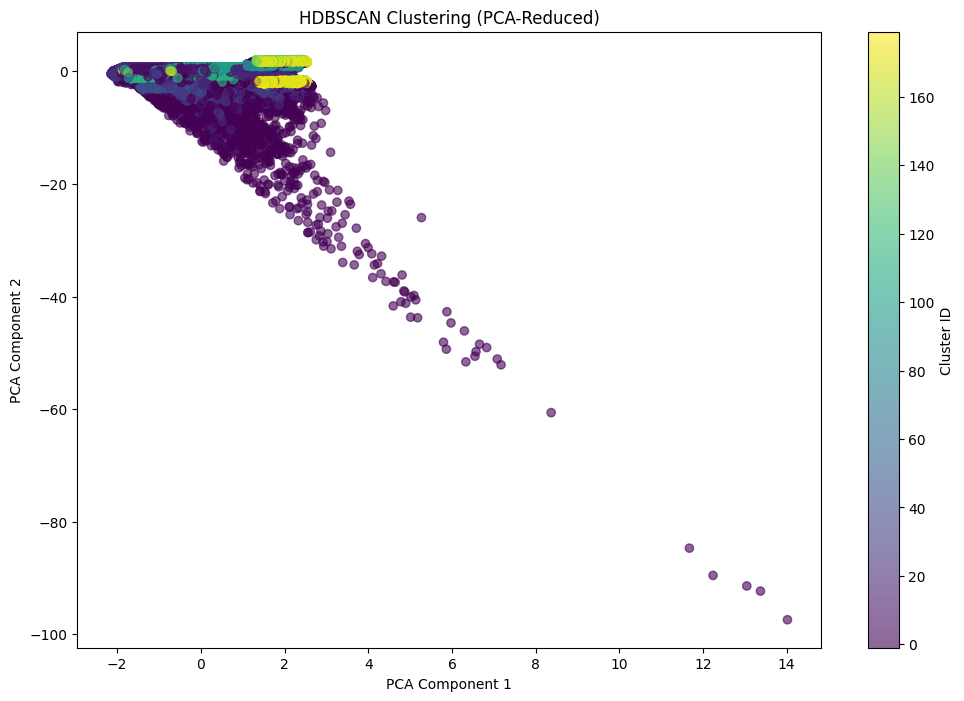

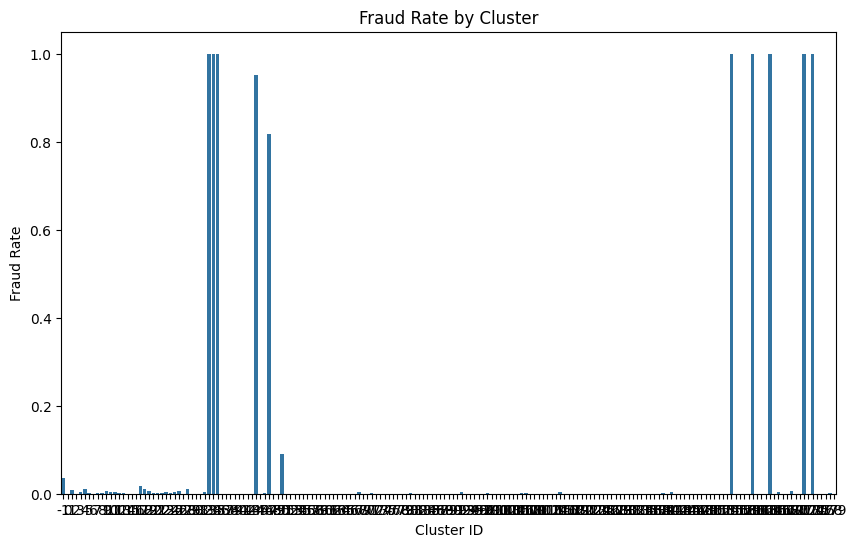

In [15]:
df=pd.read_csv(path+"/fraudTrain.csv")
result_df, hdbscan_model = run_hdbscan_fraud_detection(df)

In [16]:
print("Cluster distribution:")
print(result_df['cluster'].value_counts())

print("\nFraud rates by cluster:")
print(result_df.groupby('cluster')['is_fraud'].mean())

Cluster distribution:
cluster
 141    69663
 19     66941
 21     64742
-1      64724
 178    56739
        ...  
 74         5
 56         5
 124        5
 177        5
 97         5
Name: count, Length: 181, dtype: int64

Fraud rates by cluster:
cluster
-1      0.036463
 0      0.000000
 1      0.008368
 2      0.000000
 3      0.002959
          ...   
 175    0.000000
 176    0.000000
 177    0.000000
 178    0.001022
 179    0.000000
Name: is_fraud, Length: 181, dtype: float64
